# GlobCurrent: ocean currents with vorticity

Finsler MDS (Dagès et al., 2025) fits the canonical Randers metric $|v|+\alpha v_{\text{last}}$, whose asymmetry is a difference of potentials and sums to zero around every closed loop. A current with eddies has a nonzero circulation, so no embedding of that family can reproduce it. The moment-Randers estimator has no such constraint. This notebook runs that comparison on a real velocity field.

**Data.** Daily Eulerian surface currents of the Agulhas region (GlobCurrent, from the example data of [Parcels](https://github.com/Parcels-code/parcels-data/tree/main/data/GlobCurrent_example_data)): a 0.25° grid, 2552 ocean nodes. The file of a day (about 55 kB) is downloaded on first use into `data/globcurrent/`.

**What is real and what is modelled.** The current is real. The file has no directed distances, so they are *modelled* by Zermelo navigation: a vessel sails at constant speed $s$ relative to the water in the current $W(x)$. The travel time is a Randers metric whose unit ball is the unit disc centred at $w=W/s$, so the ground truth is known in closed form: centroid $c=w$ and $g_{BL}^{-1}=I+4ww^\top$. The strength $\beta$ (strongest current over the ship speed) plays the role of $\|b\|$.

**What is measured.** Cosine between the drift of a method and the true drift $Jc$ mapped by the Jacobian of the embedding; relative error on $\|c\|^2_{g_{BL}}$; and the *curl fraction*, the share of the asymmetry of the edges that no potential explains. `gradient ceiling` is the cosine reached by the best drift that is the gradient of a potential, $-\nabla\varphi$, which is the form of the drift of Finsler MDS.

In [1]:
import warnings
from functools import partialmethod

warnings.filterwarnings("ignore")  # deprecation notice of torch.jit at import

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import Normalize
from scipy.linalg import orthogonal_procrustes
from tqdm import tqdm

from finsler_embedding.core.embeddings import isomap_embedding
from finsler_embedding.core.operators import randers_approximation
from finsler_embedding.experiments.baselines import perrault_joncas_meila
from finsler_embedding.experiments.finsler_mds_manifolds import (
    finsler_mds_points, mds_directional_cosines, mds_strength, path_distances, run,
)
from finsler_embedding.experiments.globcurrent.curl import edge_asymmetries, potential_drift, potential_fit
from finsler_embedding.experiments.globcurrent.data import EARTH_RADIUS_KM, make_globcurrent
from finsler_embedding.experiments.legacy.evaluation import build_graph, evaluate_embedding, local_jacobian
from finsler_embedding.experiments.palette import INK, SPEED

tqdm.__init__ = partialmethod(tqdm.__init__, disable=True)  # no progress bars for the distances of the graph

BETA = 0.9       # strongest current of the day over the speed of the ship, < 1
K = 10           # neighbours of the kNN graph (Finsler MDS and the curl diagnostic)
RADIUS = 150.0   # km, radius graph of the proposed method
ALPHA = 0.5      # strength of the canonical drift of Finsler MDS
SEED = 0
DATE = "20020101"  # any day from 20020101 to 20030101 (the example data of Parcels)

## One sample: all the ocean nodes

The nodes are on the sphere (km, in $\mathbb{R}^3$); the tangent frame at a node is (east, north), in which the current has its components $(u,v)$. `data["F"]` is the Zermelo metric, `data["truth"]` the closed form of the ground truth.

In [2]:
torch.manual_seed(SEED)
np.random.seed(SEED)
data = make_globcurrent(10**6, BETA, date=DATE)  # every ocean node of the grid
X, P, F, truth, speed = data["X_graph"], data["P"], data["F"], data["truth"], data["labels"]
n = X.shape[0]
print(f"{n} ocean nodes; strongest current {np.nanmax(speed):.2f} m/s, ship speed {data['ship_speed']:.2f} m/s; "
      f"median |w| = {truth['c'].norm(dim=1).median():.2f}")

2552 ocean nodes; strongest current 1.72 m/s, ship speed 1.91 m/s; median |w| = 0.19


## The three estimators

* **Ours.** Radius graph (150 km, enlarged until the kernel is not truncated), 2D Isomap embedding, drift and centroid from the graph operators. The Jacobian $J$ of the embedding, by least squares on the neighbours in the tangent frame, maps the true drift into the embedding.
* **Perrault-Joncas & Meila (PJM).** Vector field of the antisymmetric part of the same kernel, in the same embedding.
* **Finsler MDS.** Directed shortest paths of the kNN graph, as its authors compute them (both directions of every pair of a symmetric kNN graph, each with its directed length, then Dijkstra), embedded in the canonical Randers space of dimension 3. Its drift is the last axis; on the embedded surface, its tangential part.

In [3]:
cosine = torch.nn.functional.cosine_similarity
c_norm_true = torch.einsum("ni,nij,nj->n", truth["c"], torch.linalg.inv(truth["g_bl_inv"]), truth["c"])

# Ours
W, edges, lengths, eps = build_graph(X, F, "radius", K, 1.0, 0.5, 2, 3.0, RADIUS, "cpu")
Y = isomap_embedding(X.detach(), n_components=2, n_neighbors=10)
J = local_jacobian(X.detach(), Y, P)
result = randers_approximation(W, eps, X_low=Y, m=2)
true_drift = torch.einsum("nlm,nm->nl", J, truth["c"])
metrics = evaluate_embedding(result, Y, J, truth, 2, {})

# Perrault-Joncas & Meila (undefined where the kernel is truncated and a node has no out-edge)
field = torch.as_tensor(perrault_joncas_meila.vector_field(W.numpy(), Y.numpy()), dtype=torch.float32)
finite = torch.isfinite(field).all(dim=1)

# Finsler MDS on the kNN graph (strongly connected)
_, knn_edges, knn_lengths, _ = build_graph(X, F, "knn", K, 1.0, 0.5, 2, 3.0, None, "cpu")
Z = finsler_mds_points(path_distances(knn_edges, knn_lengths, n), ALPHA, SEED)
J3 = local_jacobian(X.detach(), Z, P)
strength_mds = mds_strength(J3, ALPHA)

# Curl: best potential of the asymmetry (d_ij - d_ji) / 2 of the kNN graph, and its gradient
pairs, asymmetry = edge_asymmetries(knn_edges, knn_lengths, n)
phi, curl_fraction = potential_fit(pairs, asymmetry, n)
gradient = potential_drift(X.detach(), P, phi)  # -grad(phi) in the (east, north) frame


def summary(c):
    return dict(median=float(c.median()), q10=float(c.quantile(0.1)), positive=float((c > 0).float().mean()))


table = pd.DataFrame({
    "ours": summary(cosine(result.drift, true_drift, dim=1)) | {"relerr ||c||^2": metrics["relerr_c_norm_all"]},
    "Perrault-Joncas & Meila": summary(cosine(field[finite], true_drift[finite], dim=1)),
    "Finsler MDS": summary(mds_directional_cosines(J3, truth["c"])["tangential"])
    | {"relerr ||c||^2": float(((strength_mds - c_norm_true).abs() / c_norm_true).median())},
    "gradient ceiling": summary(cosine(gradient, truth["c"], dim=1)),
}).T
print(f"curl fraction of the asymmetry: {curl_fraction:.2f} (the share that no potential explains)")
table.round(3)

curl fraction of the asymmetry: 0.84 (the share that no potential explains)


,median,q10,positive,relerr ||c||^2
ours,0.996,0.924,0.985,0.165
Perrault-Joncas & Meila,0.996,0.918,0.986,NaN
Finsler MDS,0.440,-0.812,0.673,0.794
gradient ceiling,0.467,-0.839,0.673,NaN


## Figure

Left to right: the true currents; the best drift that is the gradient of a potential, on the same map and at the same arrow scale (what Finsler MDS can at best draw on the data); our embedding with the estimated centroid $\sqrt{\kappa}V\approx Jw$ (Isomap up to a rigid motion, same arrow scale as the data); the Finsler MDS embedding seen from the side, its drift being the vertical axis. Nodes are coloured by the speed of the current, on one scale in all the panels (pale: slow water, pink and orange: the jets).

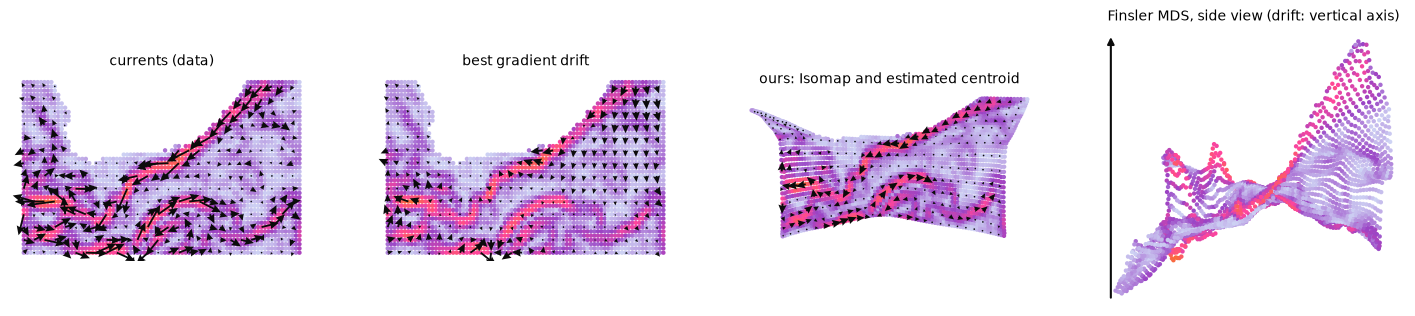

In [4]:
STRIDE = 3      # one arrow every STRIDE nodes of the grid, in both directions
ARROW_KM = 220  # length (km) of an arrow of norm one

lon, lat = data["lon"].numpy().astype(np.float64), data["lat"].numpy().astype(np.float64)  # radians
chart = EARTH_RADIUS_KM * np.stack([np.cos(lat.mean()) * (lon - lon.mean()), lat - lat.mean()], axis=1)  # km, display only
lon_deg, lat_deg = np.rad2deg(lon), np.rad2deg(lat)
ix, iy = np.rint((lon_deg - 14.875) / 0.25).astype(int), np.rint((lat_deg + 40.125) / 0.25).astype(int)  # grid indices
anchor = (ix % STRIDE == 0) & (iy % STRIDE == 0)
colors = SPEED(Normalize(0, speed.max())(speed))


def panel(ax, points, arrows, title):
    ax.scatter(*points.T, c=colors, s=10, linewidths=0, zorder=1)
    if arrows is not None:
        ax.quiver(*points[anchor].T, *(ARROW_KM * arrows[anchor]).T, angles="xy", scale_units="xy", scale=1,
                  color=INK, width=0.006, headwidth=4.5, headlength=5, zorder=3)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(title, fontsize=10)


rotation = orthogonal_procrustes(Y.numpy() - Y.numpy().mean(0), chart - chart.mean(0))[0]  # rigid motion
embedded = (Y.numpy() - Y.numpy().mean(0)) @ rotation
centroid = result.centroid.numpy() @ rotation
mds = Z.numpy() - Z.numpy().mean(0)
side = np.stack([mds[:, :2] @ np.linalg.svd(mds[:, :2], full_matrices=False)[2][0], mds[:, 2]], axis=1)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
panel(axes[0], chart, truth["c"].numpy(), "currents (data)")
panel(axes[1], chart, gradient.numpy(), "best gradient drift")
panel(axes[2], embedded, centroid, "ours: Isomap and estimated centroid")
panel(axes[3], side, None, "Finsler MDS, side view (drift: vertical axis)")
axes[3].annotate("", xy=(0.03, 0.98), xytext=(0.03, 0.02), xycoords="axes fraction",
                 arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.5))
axes[3].set_aspect("auto")
plt.show()

## Several samples

The protocol of the Swiss roll and Matsumoto experiments (`finsler_mds_manifolds`): $N=2000$ ocean nodes drawn from the grid, three seeds, two strengths. Median over the seeds of the cosine with the true drift (10% quantile over the nodes in `cos_V_q10`) and of the relative error on $\|c\|^2_{g_{BL}}$. $\beta$ only changes the speed of the ship: the same field is used, so the two strengths are not independent experiments.

Ours is run for $\theta\in\{1,0.5,0\}$, the exponent of the degree normalisation of the kernel (`ours`, `ours_theta0.5`, `ours_theta0`, same graph and embedding), and Finsler MDS for the two drift strengths $\alpha=\|\omega\|\in\{0.5,0.9\}$ (`finsler_mds_alpha0.5`, `finsler_mds_alpha0.9`). Nothing here selects $\theta$ or $\alpha$ with the ground truth, so all values are reported.

In [5]:
rows = []
for beta in (0.5, 0.9):
    for seed in range(3):
        for alpha in (ALPHA, 0.9):
            sample = run("globcurrent", 2000, beta, seed, alpha, K, thetas=(1.0, 0.5, 0.0))[0]
            for row in sample:
                if row["method"] == "finsler_mds":
                    rows.append(row | {"method": f"finsler_mds_alpha{alpha:g}"})
                elif alpha == ALPHA:  # ours (every theta), PJM and the gradient ceiling do not depend on alpha
                    rows.append(row)
runs = pd.DataFrame(rows)
runs.groupby(["beta", "method"])[["cos_V", "cos_V_q10", "relerr_c_norm", "curl_fraction"]].median().round(3)


cos_V  cos_V_q10  relerr_c_norm  curl_fraction
beta method                                                               
0.5  finsler_mds_alpha0.5   0.419     -0.803          0.880            NaN
     finsler_mds_alpha0.9   0.405     -0.792          0.886            NaN
     gradient_ceiling       0.626     -0.751            NaN          0.784
     ours                   0.994      0.887          0.255            NaN
     ours_theta0            0.994      0.884          0.257            NaN
     ours_theta0.5          0.994      0.886          0.256            NaN
     perrault_joncas_meila  0.994      0.877            NaN            NaN
0.9  finsler_mds_alpha0.5   0.448     -0.816          0.771            NaN
     finsler_mds_alpha0.9   0.415     -0.812          0.794            NaN
     gradient_ceiling       0.559     -0.797            NaN          0.793
     ours                   0.994      0.891          0.209            NaN
     ours_theta0            0.994      0.891          0.208            NaN
     ours_theta0.5          0.994      0.890          0.209            NaN
     perrault_joncas_meila  0.994      0.875            NaN            NaN

## Ours with the identity map instead of Isomap

The Isomap of this domain is warped by the coast (the land notch). Does the estimate depend on it? Here the kernel and the drift are computed in the data coordinates, the identity map (the nodes in $\mathbb{R}^3$, in km): no embedding is learned and the Jacobian is the tangent frame. Same samples and graphs as above (three seeds, two strengths), median over the seeds; Perrault-Joncas & Meila is run in the same coordinates.

In [6]:
def ours_and_pjm(Y, J, W, eps, truth):
    """Cosine with the true drift (median and 10% quantile) of ours and PJM, and relative error of ours on ||c||^2."""
    result = randers_approximation(W, eps, X_low=Y, m=2)
    true_drift = torch.einsum("nlm,nm->nl", J, truth["c"])
    cos_ours = cosine(result.drift, true_drift, dim=1)
    field = torch.as_tensor(perrault_joncas_meila.vector_field(W.numpy(), Y.numpy()), dtype=torch.float32)
    defined = torch.isfinite(field).all(dim=1)
    cos_pjm = cosine(field[defined], true_drift[defined], dim=1)
    return {
        "ours cos": float(cos_ours.median()), "ours cos q10": float(cos_ours.quantile(0.1)),
        "ours relerr ||c||^2": evaluate_embedding(result, Y, J, truth, 2, {})["relerr_c_norm_all"],
        "PJM cos": float(cos_pjm.median()), "PJM cos q10": float(cos_pjm.quantile(0.1)),
    }


rows = []
for beta in (0.5, 0.9):
    for seed in range(3):
        torch.manual_seed(seed)
        np.random.seed(seed)
        sample = make_globcurrent(2000, beta, date=DATE)
        W_s, _, _, eps_s = build_graph(sample["X_graph"], sample["F"], "radius", K, 1.0, 0.5, 2, 3.0, RADIUS, "cpu")
        Y_iso = isomap_embedding(sample["X_graph"].detach(), n_components=2, n_neighbors=10)
        J_iso = local_jacobian(sample["X_chart"].detach(), Y_iso, sample["P"])
        for name, Y_s, J_s in [("Isomap", Y_iso, J_iso), ("identity map", sample["X_chart"].detach(), sample["P"])]:
            rows.append({"beta": beta, "embedding": name} | ours_and_pjm(Y_s, J_s, W_s, eps_s, sample["truth"]))
pd.DataFrame(rows).groupby(["beta", "embedding"]).median().round(3)

ours cos  ours cos q10  ours relerr ||c||^2  PJM cos  \
beta embedding                                                            
0.5  Isomap           0.994         0.887                0.255    0.994   
     identity map     0.994         0.891                0.252    0.993   
0.9  Isomap           0.994         0.891                0.209    0.994   
     identity map     0.993         0.891                0.206    0.993   

                   PJM cos q10  
beta embedding                  
0.5  Isomap              0.877  
     identity map        0.863  
0.9  Isomap              0.875  
     identity map        0.866

The two embeddings give the same estimate. Ours has a cosine of 0.993 to 0.994 with the true drift and a relative error on $\|c\|^2_{g_{BL}}$ of 0.25 ($\beta=0.5$) and 0.21 ($\beta=0.9$) in both, and Perrault-Joncas & Meila is unchanged too. The warp of the Isomap by the coast does not matter, and the data coordinates do not improve the estimate: the error on the strength does not come from the choice of embedding.